<div align="center">

# 🚗🚦 Driving Scene Object Detection & Tracking
### 🔍 OpenCV  ➕  🤖 YOLOv8n  ➕  🎯 ByteTrack

![Python](https://img.shields.io/badge/Python-3.10+-3776AB?logo=python&logoColor=white)
![OpenCV](https://img.shields.io/badge/OpenCV-Computer%20Vision-5C3EE8?logo=opencv&logoColor=white)
![YOLOv8](https://img.shields.io/badge/YOLOv8n-Ultralytics-00FFFF)
![Status](https://img.shields.io/badge/Status-Portfolio%20Project-brightgreen)

</div>

---

## 📌 What is this project doing?
This project analyses **dashcam driving videos (BDD100K)** and detects and tracks road objects such as 🚗 cars, 🚚 trucks, 🚌 buses, 🚶 people, 🚦 traffic lights and 🛑 signs. It combines two approaches:

1. 🧰 **Classical computer vision (OpenCV):** Gaussian blur, grayscale, adaptive threshold and contour extraction.
2. 🧠 **Deep learning (YOLOv8n + ByteTrack):** real-time object detection, with a persistent ID for each object across frames.

It then measures ⚡ speed (FPS), 📦 detections per frame, 🏷️ classes found and 🎚️ detection confidence. To see how the model behaves in different scenes, the same model is run on several different videos and on your own uploaded images.

## 🎯 What is the outcome?
- 🎬 An annotated output video with boxes, class names and track IDs.
- 📄 Metrics tables (CSV): FPS, objects per frame, unique tracked objects, confidence.
- 📊 Charts: sample frames, FPS, objects per frame, class counts, confidence per video.
- 🖼️ Detections on your own uploaded images, shown as before/after pictures.
- 🏁 A final summary based on the project's own criteria, plus its limits.

---

## 🏆 Saved results from the author's run
| 🧪 Metric | 📈 Value |
|---|---|
| 🎞️ Videos processed | **5** |
| 🖼️ Frames processed | **750** |
| ⚡ Average FPS | **57.3** |
| 🎚️ Average confidence | **0.548** |
| ⚠️ Low-confidence detections (< 0.4) | **20.8 %** |
| 📷 Additional images | **6** |

> 📝 These are the **saved outputs of the author's run**. They depend on the hardware, the randomly chosen videos and the model settings, so your numbers will differ a little.

> ⚠️ **Important limitation:** no ground-truth labels are used here, so precision, recall and mAP are **not** reported. **Detection confidence is not the same as accuracy.**

---

## 🗺️ Table of contents
| # | 📚 Section | # | 📚 Section |
|---|---|---|---|
| 1 | 📦 Install | 13 | 🖼️ Your own images |
| 2 | ⚙️ Imports & settings | 14 | 🔎 Detections on your images |
| 3 | 🤖 Load model | 15 | 🏁 Conclusion |
| 3b | 🖥️ Environment & hardware | 16 | 🆚 Per-video comparison |
| 4 | 🎲 Pick videos | 17 | 📉 Confidence distribution |
| 5 | 🛠️ Processing function | 18 | 🔥 Class share heatmap |
| 6 | ▶️ Run on videos | 19 | 🎚️ Confidence by class |
| 7 | 📋 Summary table | 20 | ⏱️ Track lifetime analysis |
| 8 | 🖼️ Sample frames | 21 | 🐢 Speed vs busyness |
| 9 | ⚡ FPS | 22 | 🧐 Possible false detections |
| 10 | 📦 Detections per frame | 23 | 📋 Final comparison table |
| 11 | 🏷️ Classes detected | 24 | 🎓 Limitations & next steps |
| 12 | 🎚️ Confidence per video | | |

---
## 📦 Step 1: Install libraries
`lap` is required by the ByteTrack tracker. 🧩

> 💡 On Kaggle/Colab this cell installs everything. Locally you can instead run `pip install -r requirements.txt`.

In [64]:
!pip install -q ultralytics lap

---
## ⚙️ Step 2: Imports and settings
All paths and parameters are defined once here. 🎛️

> 📂 **Dataset:** the driving videos are **not** included in this repository. Add the Kaggle dataset *Driving Video with Object Tracking* (BDD100K videos) to your notebook, or change `DATASET_PATH` to the folder that holds your `.mov` videos.

In [65]:
import os, glob, time, random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 📂 Change this path if your videos are stored somewhere else
DATASET_PATH = "/kaggle/input/datasets/robikscube/driving-video-with-object-tracking"
OUT_DIR      = "/kaggle/working"   # output folder (use e.g. "./outputs" when running locally)
N_VIDEOS     = 5      # number of videos to analyse
MAX_FRAMES   = 150    # frames per video
CONF         = 0.25   # detection confidence threshold
SEED         = 42

os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)
random.seed(SEED)

---
## 🤖 Step 3: Load the YOLO model and warm it up
The first inference is always slow (model initialisation). 🐌➡️🚀 A dummy run keeps it from distorting the speed measurements.

In [66]:
model = YOLO("yolov8n.pt")
model.predict(np.zeros((640, 640, 3), dtype=np.uint8), verbose=False)
print("Model loaded and warmed up.")

Model loaded and warmed up.


---
## 🖥️ Step 3b: Environment and hardware (for reproducibility)
Run this cell to record the **exact versions** and the **device (CPU or GPU)** used for your run. 🔁
Copy the printed versions into `requirements.txt` and the README.

> ⏱️ **What the FPS includes:** the measured time covers the OpenCV preprocessing **and** YOLO + ByteTrack tracking. It does **not** include video reading or writing.

In [67]:
import sys, platform
from importlib.metadata import version, PackageNotFoundError
import torch

def pkg_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"

device = "GPU: " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.platform())
print("Device      :", device)
print("-" * 40)
for name in ["ultralytics", "opencv-python", "numpy", "pandas", "matplotlib", "torch", "lap"]:
    print(f"{name:<14}:", pkg_version(name))
print("-" * 40)
print("Note: reported FPS = OpenCV preprocessing + YOLO/ByteTrack tracking (no video I/O).")

Python      : 3.13.15
Platform    : Linux-6.18.55+-x86_64-with-glibc2.39
Device      : GPU: Tesla T4
----------------------------------------
ultralytics   : 8.4.208
opencv-python : 4.14.0.94
numpy         : 2.1.3
pandas        : 2.3.3
matplotlib    : 3.10.0
torch         : 2.11.0+cu128
lap           : 0.5.14
----------------------------------------
Note: reported FPS = OpenCV preprocessing + YOLO/ByteTrack tracking (no video I/O).


---
## 🎲 Step 4: Find the videos and pick several at random
Using several different videos, not just the first one, shows whether the results change between scenes. 🌆🌃🛣️

In [68]:
all_videos = sorted(glob.glob(os.path.join(DATASET_PATH, "**", "*.mov"), recursive=True))
print("Total videos found:", len(all_videos))
if not all_videos:
    raise FileNotFoundError("No .mov videos found. Check DATASET_PATH.")

videos = random.sample(all_videos, min(N_VIDEOS, len(all_videos)))
for v in videos:
    print(" ", os.path.basename(v))

Total videos found: 1000
  01c6a5ce-7dba0d93.mov
  0049e5b8-725e21a0.mov
  000f157f-37797ff9.mov
  02124b78-5bae69c1.mov
  00beeb02-50440dcd.mov


---
## 🛠️ Step 5: Processing function
For each frame:
1. 🧰 **Classical CV:** blur, grayscale, adaptive threshold, contours.
2. 🤖 **YOLO and ByteTrack** run on the **clean** frame, so the contours don't disturb detection.
3. 📊 Per-frame and per-detection statistics are recorded.

In [69]:
def process_video(path, idx, save_video=False):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open {path}")
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 30
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = None
    if save_video:
        writer = cv2.VideoWriter(f"{OUT_DIR}/processed_{idx}.mp4",
                                 cv2.VideoWriter_fourcc(*"mp4v"), fps_in, (w, h))
    model.predictor = None   # reset tracker between videos
    frame_rows, det_rows, samples = [], [], {}
    n = 0
    while n < MAX_FRAMES:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()

        gray = cv2.cvtColor(cv2.GaussianBlur(frame, (5, 5), 0), cv2.COLOR_BGR2GRAY)
        mask = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, 11, 2)
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        n_cnt = sum(cv2.contourArea(c) >= 100 for c in cnts)

        res = model.track(frame, persist=True, tracker="bytetrack.yaml",
                          conf=CONF, verbose=False)[0]
        ms = (time.perf_counter() - t0) * 1000

        boxes = res.boxes
        k = len(boxes) if boxes is not None else 0
        if k:
            ids = boxes.id.int().tolist() if boxes.id is not None else [None] * k
            for c, cf, tid in zip(boxes.cls.int().tolist(), boxes.conf.tolist(), ids):
                det_rows.append(dict(video=idx, frame=n, cls=res.names[c], conf=cf, track_id=tid))

        frame_rows.append(dict(video=idx, frame=n, objects=k, contours=n_cnt, ms=ms, fps=1000 / ms))

        annotated = res.plot()
        cv2.putText(annotated, f"Frame {n} | Objects {k}", (20, 35),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
        if n in (0, MAX_FRAMES // 2, MAX_FRAMES - 1):
            samples[n] = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
        if writer:
            writer.write(annotated)
        n += 1
    cap.release()
    if writer:
        writer.release()
    return pd.DataFrame(frame_rows), pd.DataFrame(det_rows), samples

---
## ▶️ Step 6: Run on all selected videos
Results are saved to CSV 💾. Only the first video is written out as an annotated video, to save disk space.

In [70]:
frames_l, dets_l, samples_all = [], [], {}
for i, p in enumerate(videos):
    f, d, s = process_video(p, i, save_video=(i == 0))
    frames_l.append(f); dets_l.append(d); samples_all[i] = s
    print(f"video {i}: {len(f)} frames, {len(d)} detections")

frames_df = pd.concat(frames_l, ignore_index=True)
dets_df   = pd.concat(dets_l, ignore_index=True)
frames_df.to_csv(f"{OUT_DIR}/frame_metrics.csv", index=False)
dets_df.to_csv(f"{OUT_DIR}/detections.csv", index=False)

video 0: 150 frames, 1594 detections
video 1: 150 frames, 730 detections
video 2: 150 frames, 389 detections
video 3: 150 frames, 1295 detections
video 4: 150 frames, 31 detections


---
## 📋 Step 7: Summary table
Frame 0 is excluded from the speed numbers because it includes tracker start-up. 🚦

In [71]:
speed = frames_df[frames_df.frame > 0]
summary = pd.DataFrame({
    "frames":        frames_df.groupby("video").size(),
    "mean_objects":  frames_df.groupby("video").objects.mean().round(2),
    "mean_conf":     dets_df.groupby("video").conf.mean().round(3),
    "unique_tracks": dets_df.dropna(subset=["track_id"]).groupby("video").track_id.nunique(),
    "mean_fps":      speed.groupby("video").fps.mean().round(1),
    "mean_contours": frames_df.groupby("video").contours.mean().round(0),
})
display(summary)
print("Overall mean FPS:", round(speed.fps.mean(), 1))
print("Overall mean confidence:", round(dets_df.conf.mean(), 3))

,frames,mean_objects,mean_conf,unique_tracks,mean_fps,mean_contours
video,,,,,,
0,150,10.63,0.514,46,44.4,77.0
1,150,4.87,0.607,29,52.2,14.0
2,150,2.59,0.500,39,53.4,4.0
3,150,8.63,0.570,55,48.7,27.0
4,150,0.21,0.620,5,58.5,24.0


Overall mean FPS: 51.4
Overall mean confidence: 0.548


---
## 🖼️ Step 8: Sample frames from every video
A visual check of the detections in different scenes (first, middle and last frame of each video). 👀

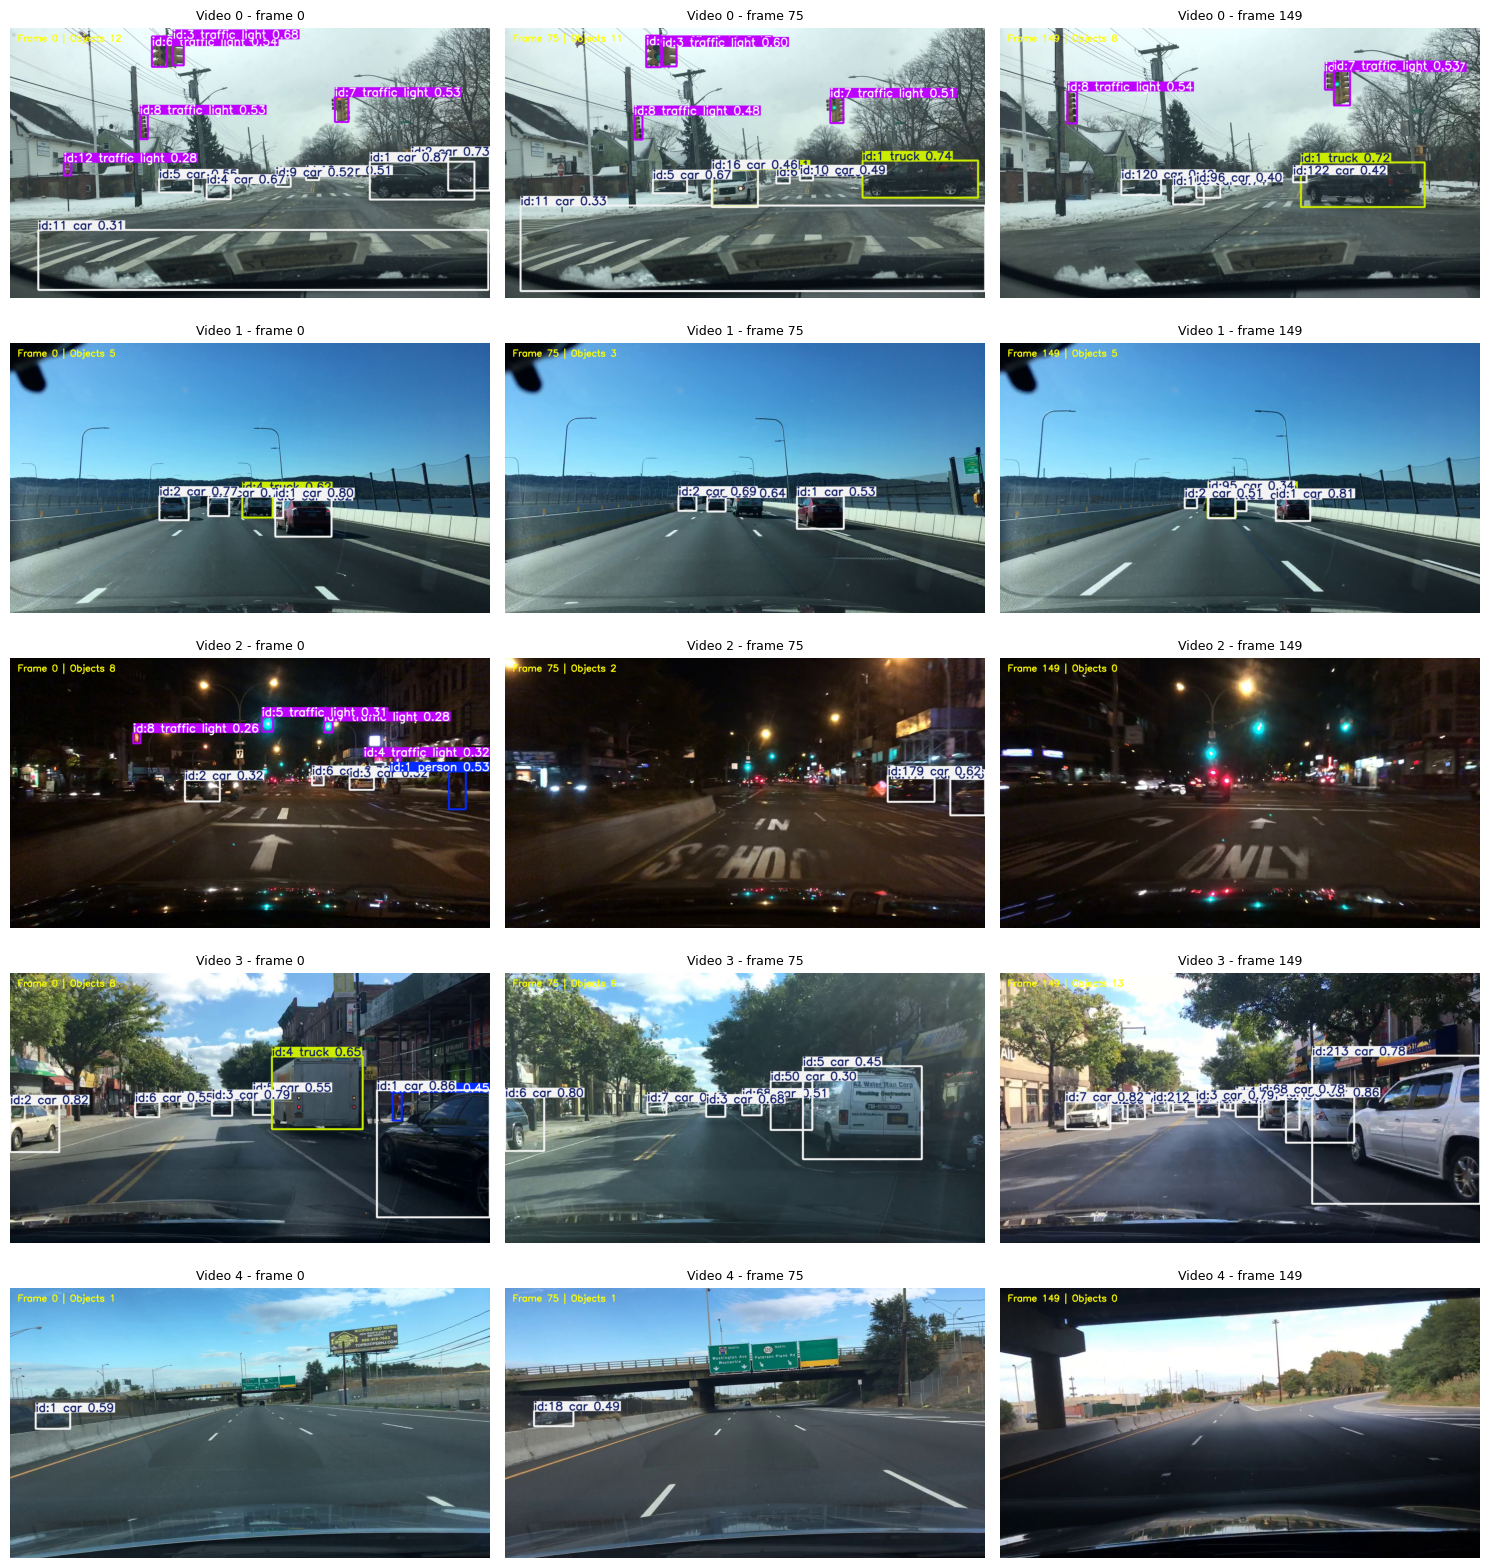

In [72]:
fig, axes = plt.subplots(len(videos), 3, figsize=(15, 3.2 * len(videos)))
axes = np.atleast_2d(axes)
for i in range(len(videos)):
    for j, fn in enumerate(sorted(samples_all[i])):
        axes[i, j].imshow(samples_all[i][fn]); axes[i, j].axis("off")
        axes[i, j].set_title(f"Video {i} - frame {fn}", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/1_sample_frames.png", dpi=120)
plt.show()

---
## ⚡ Step 9: Processing speed (FPS)
This project uses **about 20 FPS** as its own real-time target (a threshold chosen by the author, not a universal standard). 🎯
Big dips usually mean crowded scenes. 🚗🚗🚗

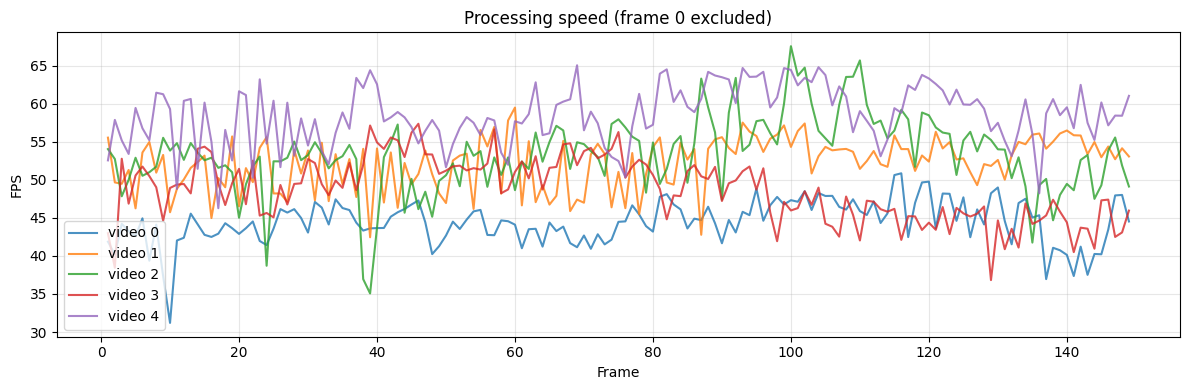

In [73]:
plt.figure(figsize=(12, 4))
for v, g in speed.groupby("video"):
    plt.plot(g.frame, g.fps, label=f"video {v}", alpha=.8)
plt.xlabel("Frame"); plt.ylabel("FPS"); plt.title("Processing speed (frame 0 excluded)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/2_fps.png", dpi=120)
plt.show()

---
## 📦 Step 10: Detections per frame
Stable curves mean steady detection. 📈 Sudden drops to 0 can mean missed objects, or simply an empty road. 🛣️

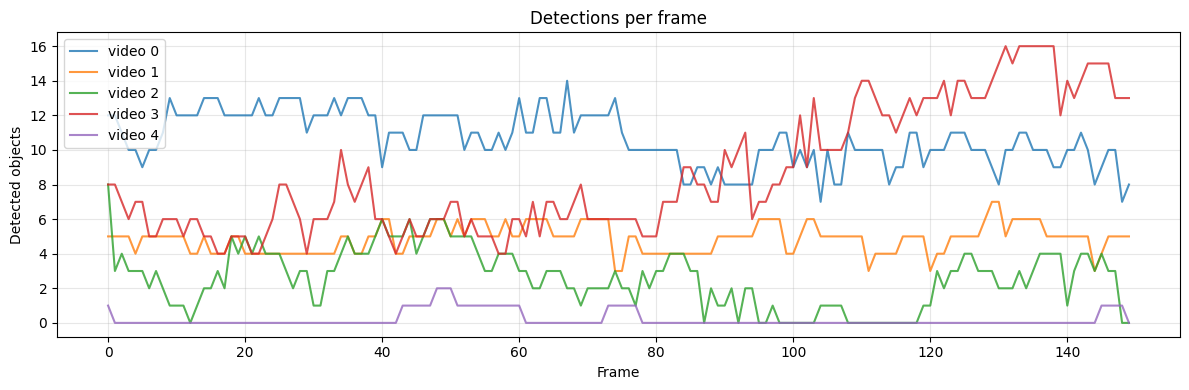

In [74]:
plt.figure(figsize=(12, 4))
for v, g in frames_df.groupby("video"):
    plt.plot(g.frame, g.objects, label=f"video {v}", alpha=.8)
plt.xlabel("Frame"); plt.ylabel("Detected objects"); plt.title("Detections per frame")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/3_objects_per_frame.png", dpi=120)
plt.show()

---
## 🏷️ Step 11: Which classes were detected?
For driving scenes you should mostly see 🚗 car, 🚶 person, 🚚 truck, 🚦 traffic light and 🚌 bus.

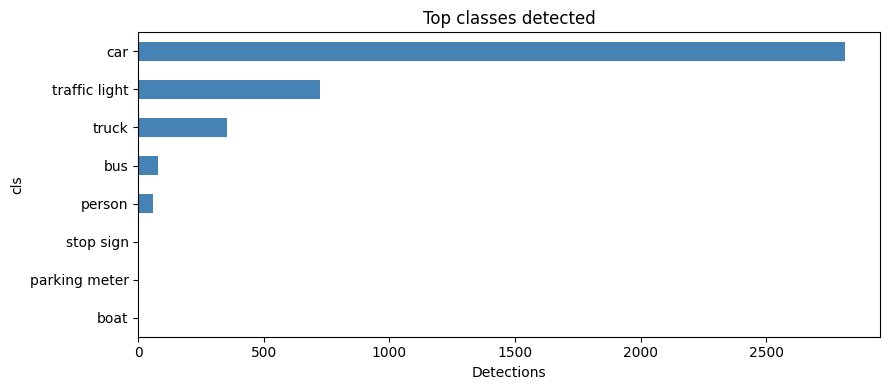

In [75]:
counts = dets_df.cls.value_counts().head(10)
plt.figure(figsize=(9, 4))
counts[::-1].plot.barh(color="steelblue")
plt.xlabel("Detections"); plt.title("Top classes detected"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/4_class_counts.png", dpi=120)
plt.show()

---
## 🎚️ Step 12: Confidence comparison across videos
Similar boxes across videos mean the model's **confidence scores** are similar in different scenes. A video with much lower confidence is a harder scene (🌙 night, 🌧️ rain, ☀️ glare).

> ⚠️ Confidence scores alone cannot prove accuracy or generalization. That would need ground-truth labels.

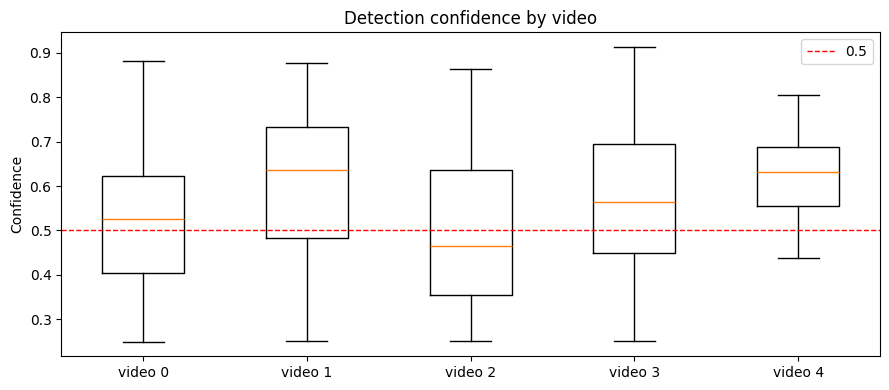

In [76]:
vids = sorted(dets_df.video.unique())
plt.figure(figsize=(9, 4))
plt.boxplot([dets_df[dets_df.video == v].conf.values for v in vids],
            tick_labels=[f"video {v}" for v in vids])
plt.axhline(0.5, color="red", ls="--", lw=1, label="0.5")
plt.ylabel("Confidence"); plt.title("Detection confidence by video")
plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/5_confidence_by_video.png", dpi=120)
plt.show()

---
## 🖼️ Step 13: Detect objects in YOUR OWN images
**📝 How to use:**
1. In Kaggle click **Add Input** (right panel), then **Upload**, then **New Dataset**.
2. Upload your `.jpg` / `.png` images and give the dataset a name.
3. Set `MY_IMAGES_DIR` below to the path shown in the right panel (usually `/kaggle/input/<your-dataset-name>`).
4. Running locally? Point `MY_IMAGES_DIR` to any folder with images.

The model runs on each image and shows the original next to the detection result. 👈👉 These images are different from the driving videos, so they show how the model behaves on other kinds of pictures.

> 🔒 Only use images you own or have permission to share.

In [77]:
# 📂 Replace with the path of YOUR image dataset
MY_IMAGES_DIR = "/kaggle/input/your-image-dataset"

exts = ("*.jpg", "*.jpeg", "*.png", "*.webp")
my_images = sorted(sum([glob.glob(os.path.join(MY_IMAGES_DIR, "**", e), recursive=True)
                        for e in exts], []))
print("Images found:", len(my_images))
if not my_images:
    print("No images found. Check MY_IMAGES_DIR (the later image cells will be skipped safely).")

Images found: 0
No images found. Check MY_IMAGES_DIR (the later image cells will be skipped safely).


---
## 🔎 Step 14: Show detections on your images

In [78]:
img_rows = []
for p in my_images:
    img = cv2.imread(p)
    if img is None:
        continue
    res = model.predict(img, conf=CONF, verbose=False)[0]
    shown = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original"); ax[0].axis("off")
    ax[1].imshow(shown); ax[1].set_title(f"Detected: {len(res.boxes)} objects"); ax[1].axis("off")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/mine_{os.path.basename(p)}.png", dpi=110)
    plt.show()

    for c, cf in zip(res.boxes.cls.int().tolist(), res.boxes.conf.tolist()):
        img_rows.append(dict(image=os.path.basename(p), cls=res.names[c], conf=cf))

img_df = pd.DataFrame(img_rows)
if len(img_df):
    display(img_df.groupby("image").agg(objects=("cls", "size"),
                                         mean_conf=("conf", "mean")).round(3))

---
## 🏁 Step 15: Conclusion
The summary below is computed from the numbers above. 🧮
It checks the **project's own criteria** (chosen by the author, not universal standards) for speed and confidence consistency. It does **not** measure true accuracy, because there are no ground-truth labels. 🚫🎯

In [79]:
share_low   = (dets_df.conf < 0.4).mean()
conf_spread = summary.mean_conf.max() - summary.mean_conf.min()
fps_mean    = speed.fps.mean()

# Project criteria (chosen by the author - NOT universal standards)
FPS_TARGET, SPREAD_MAX, LOW_SHARE_MAX = 20, 0.08, 0.5

print(f"Average processing speed:              {fps_mean:.1f} FPS  (project target: >= {FPS_TARGET})")
print(f"Low-confidence detections (<0.4):      {share_low:.1%}  (project limit: < {LOW_SHARE_MAX:.0%})")
print(f"Mean-confidence spread across videos:  {conf_spread:.3f}  (project limit: < {SPREAD_MAX})")
if len(img_df):
    print(f"Mean confidence on your own images:    {img_df.conf.mean():.3f}")

meets = conf_spread < SPREAD_MAX and share_low < LOW_SHARE_MAX and fps_mean >= FPS_TARGET
print()
if meets:
    print("Result: MEETS the project's criteria - fast, with similar confidence across videos.")
else:
    print("Result: MIXED - not all project criteria were met; check the confidence chart and sample frames.")
print("Limit: true accuracy (mAP / precision / recall) needs BDD100K ground-truth labels.")

Average processing speed:              51.4 FPS  (project target: >= 20)
Low-confidence detections (<0.4):      20.8%  (project limit: < 50%)
Mean-confidence spread across videos:  0.120  (project limit: < 0.08)

Result: MIXED - not all project criteria were met; check the confidence chart and sample frames.
Limit: true accuracy (mAP / precision / recall) needs BDD100K ground-truth labels.


---
## 🆚 Step 16: Per-video comparison
Compares scene busyness 🚗, tracked objects 🎯 and confidence 🎚️ for each video.

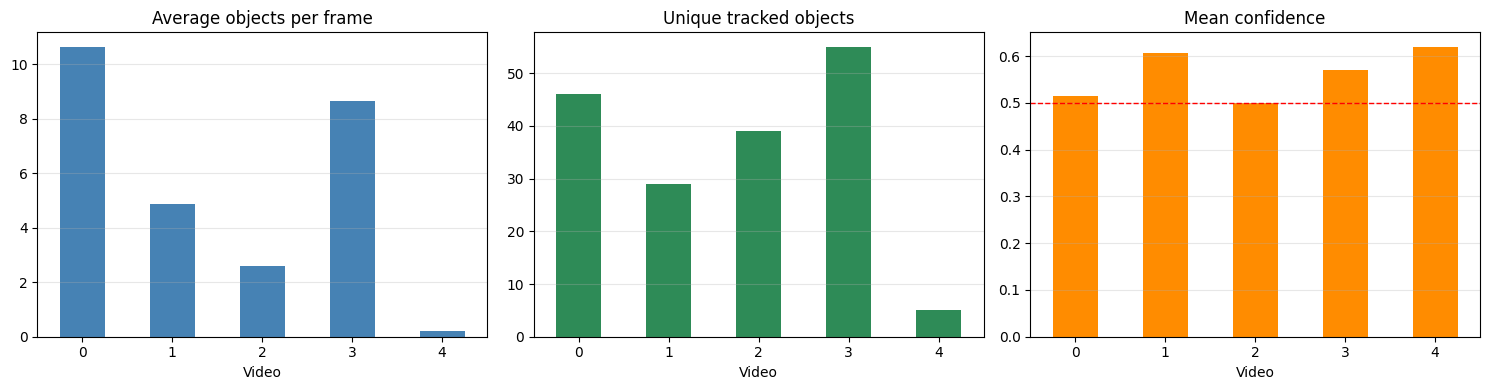

In [80]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
summary.mean_objects.plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Average objects per frame"); ax[0].set_xlabel("Video")
summary.unique_tracks.plot.bar(ax=ax[1], color="seagreen")
ax[1].set_title("Unique tracked objects"); ax[1].set_xlabel("Video")
summary.mean_conf.plot.bar(ax=ax[2], color="darkorange")
ax[2].axhline(0.5, color="red", ls="--", lw=1)
ax[2].set_title("Mean confidence"); ax[2].set_xlabel("Video")
for a in ax:
    a.tick_params(axis="x", rotation=0); a.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/6_video_comparison.png", dpi=120)
plt.show()

---
## 📉 Step 17: Confidence distribution
Shows how confident the model is overall. 🎚️ Detections below 0.4 are the low-confidence ones. 🔴

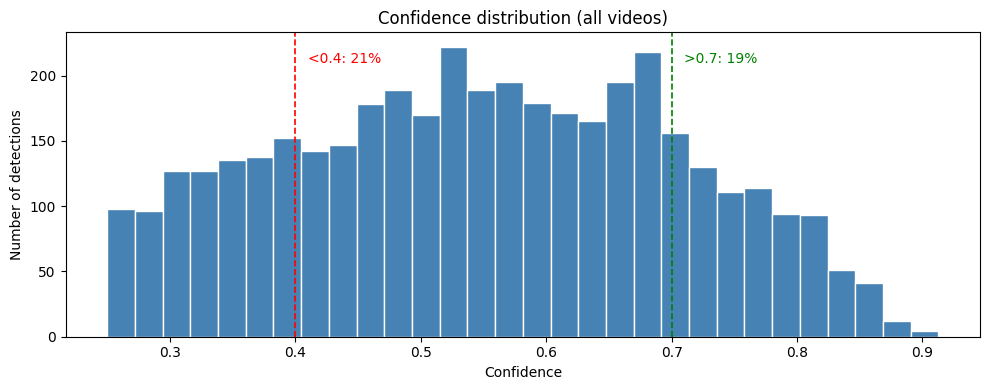

In [81]:
plt.figure(figsize=(10, 4))
plt.hist(dets_df.conf, bins=30, color="steelblue", edgecolor="white")
for x, c in [(0.4, "red"), (0.7, "green")]:
    plt.axvline(x, color=c, ls="--", lw=1.2)
plt.text(0.41, plt.ylim()[1]*0.9, f"<0.4: {(dets_df.conf < 0.4).mean():.0%}", color="red")
plt.text(0.71, plt.ylim()[1]*0.9, f">0.7: {(dets_df.conf > 0.7).mean():.0%}", color="green")
plt.xlabel("Confidence"); plt.ylabel("Number of detections")
plt.title("Confidence distribution (all videos)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/7_conf_hist.png", dpi=120)
plt.show()

---
## 🔥 Step 18: What does each video contain?
Heatmap of class share (%) per video. Different rows mean different kinds of scenes, such as 🏙️ city, 🛣️ highway or 🌙 night.

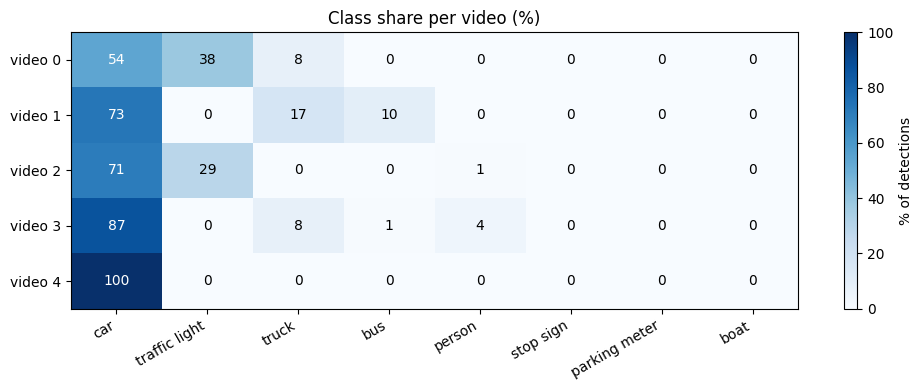

In [82]:
top = dets_df.cls.value_counts().head(8).index
ct  = pd.crosstab(dets_df.video, dets_df.cls)[top]
pct = ct.div(ct.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10, 4))
plt.imshow(pct.values, cmap="Blues", aspect="auto")
plt.xticks(range(len(top)), top, rotation=30, ha="right")
plt.yticks(range(len(pct)), [f"video {v}" for v in pct.index])
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        plt.text(j, i, f"{pct.values[i, j]:.0f}", ha="center", va="center",
                 color="white" if pct.values[i, j] > 50 else "black")
plt.colorbar(label="% of detections")
plt.title("Class share per video (%)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/8_class_heatmap.png", dpi=120)
plt.show()

---
## 🎚️ Step 19: Detection confidence by class
Confidence per class. Lower boxes are classes with lower confidence scores (often small or distant objects). 🔭

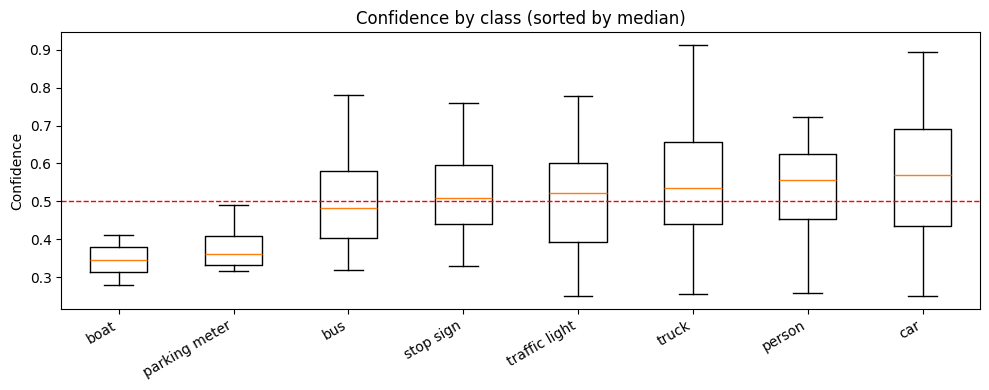

In [83]:
top = dets_df.cls.value_counts().head(8).index
order = dets_df[dets_df.cls.isin(top)].groupby("cls").conf.median().sort_values().index

plt.figure(figsize=(10, 4))
plt.boxplot([dets_df[dets_df.cls == c].conf.values for c in order],
            tick_labels=order, vert=True)
plt.axhline(0.5, color="red", ls="--", lw=1)
plt.xticks(rotation=30, ha="right"); plt.ylabel("Confidence")
plt.title("Confidence by class (sorted by median)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/9_conf_by_class.png", dpi=120)
plt.show()

---
## ⏱️ Step 20: Track lifetime analysis
How many frames each tracked object survives. 🎯 Many very short tracks can point to flickering detections or ID switches, but confirming that needs ground-truth tracking labels.

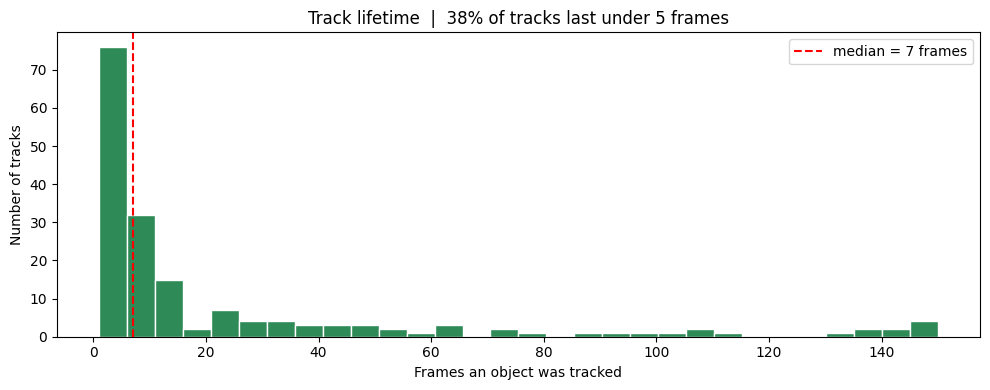

In [84]:
life = (dets_df.dropna(subset=["track_id"])
        .groupby(["video", "track_id"]).size())

plt.figure(figsize=(10, 4))
plt.hist(life, bins=30, color="seagreen", edgecolor="white")
plt.axvline(life.median(), color="red", ls="--", label=f"median = {life.median():.0f} frames")
plt.xlabel("Frames an object was tracked"); plt.ylabel("Number of tracks")
plt.title(f"Track lifetime  |  {(life < 5).mean():.0%} of tracks last under 5 frames")
plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/10_track_lifetime.png", dpi=120)
plt.show()

---
## 🐢 Step 21: Does a busier scene slow the model down?
Each dot is one frame. 🔵 A flat trend means the speed stays similar even in crowded scenes.

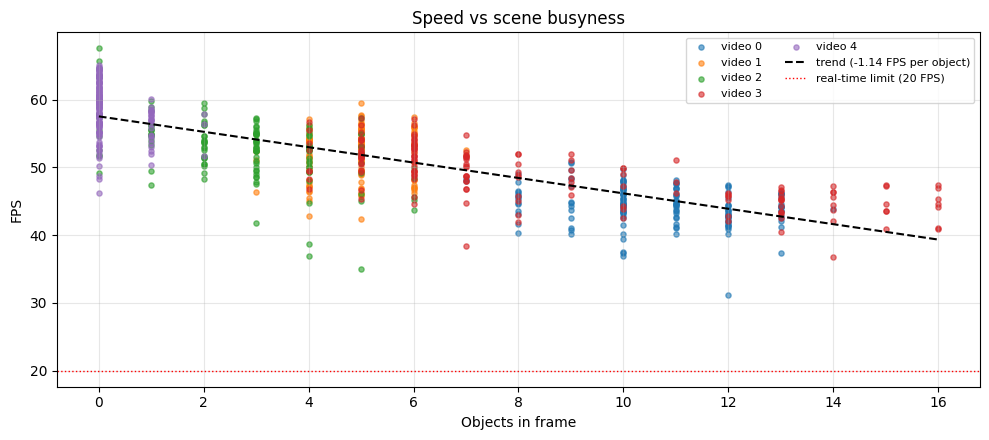

In [85]:
plt.figure(figsize=(10, 4.5))
for v, g in speed.groupby("video"):
    plt.scatter(g.objects, g.fps, s=14, alpha=.6, label=f"video {v}")
m, b = np.polyfit(speed.objects, speed.fps, 1)
xs = np.linspace(speed.objects.min(), speed.objects.max(), 50)
plt.plot(xs, m * xs + b, "k--", lw=1.5, label=f"trend ({m:.2f} FPS per object)")
plt.axhline(20, color="red", ls=":", lw=1, label="real-time limit (20 FPS)")
plt.xlabel("Objects in frame"); plt.ylabel("FPS")
plt.title("Speed vs scene busyness")
plt.legend(ncol=2, fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/11_fps_vs_objects.png", dpi=120)
plt.show()

---
## 🧐 Step 22: My images – possible false detections
Images with no road objects (🏢 building, 🏠 home, 🍎 fruits) should have few detections. If they show many low-confidence detections, these are **possible false detections**. Confirming them needs manual checking or labels.

In [86]:
if not img_df.empty:
    per_img = img_df.groupby("image").agg(
        objects=("cls", "size"),
        mean_conf=("conf", "mean"),
        low_conf=("conf", lambda s: (s < 0.4).sum()),
    )
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    per_img[["objects", "low_conf"]].plot.bar(ax=ax[0], color=["steelblue", "tomato"])
    ax[0].set_title("Detections per image (low = confidence < 0.4)")
    ax[0].tick_params(axis="x", rotation=30)

    per_img.mean_conf.plot.bar(ax=ax[1], color="darkorange")
    ax[1].axhline(0.5, color="red", ls="--", lw=1)
    ax[1].set_title("Mean confidence per image")
    ax[1].tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/12_own_images.png", dpi=120)
    plt.show()

    display(img_df.sort_values("conf", ascending=False).round(2).head(15))
else:
    print("No images were processed. Skipping image comparison.")

No images were processed. Skipping image comparison.


---
## 📋 Step 23: Final comparison table
Per-video summary of detection and tracking statistics. 📊
The colours are only a visual aid for comparing videos. They are **not** a quality verdict (for example, more unique tracks does not automatically mean better tracking). 🎨

In [87]:
display(summary.style
        .background_gradient(cmap="RdYlGn", subset=["mean_conf", "mean_fps", "unique_tracks"])
        .format(precision=2)
        .set_caption("Per-video comparison: detection and tracking statistics"))

,frames,mean_objects,mean_conf,unique_tracks,mean_fps,mean_contours
video,,,,,,
0,150,10.63,0.51,46,44.40,77.00
1,150,4.87,0.61,29,52.20,14.00
2,150,2.59,0.50,39,53.40,4.00
3,150,8.63,0.57,55,48.70,27.00
4,150,0.21,0.62,5,58.50,24.00


---
## 🎓 Step 24: Limitations and next steps

### ⚠️ Limitations
- 🚫 **No ground truth:** precision, recall and mAP are not computed. Confidence is **not** accuracy.
- 🎲 Only **5 random videos** and **150 frames each** were analysed, so results can change with another random selection.
- 🎚️ The thresholds (20 FPS, confidence spread < 0.08, low confidence < 0.4) are **the project's own choices**.
- 🖥️ FPS depends on the hardware (CPU or GPU) and excludes video reading and writing.
- 🔁 Track statistics (unique tracks, lifetime) cannot measure ID switches without tracking labels.

### 🚀 Possible next steps
1. 🏷️ Evaluate with BDD100K labels (mAP, precision, recall).
2. 🔬 Compare YOLOv8n with larger models (YOLOv8s / YOLOv8m).
3. 🌙 Test separately on day, night and rainy scenes.
4. 🎯 Evaluate tracking with MOT metrics (IDF1, MOTA).

---
<div align="center">

### ✅ Thanks for reading! If you liked this project, give it a ⭐ on GitHub.
Made with ❤️ using Python, OpenCV and YOLOv8

</div>